In [25]:
from flowrec.data.datamodule import AmazonReviewDataConfig, AmazonReviewDataModule
from flowrec.item_representation.content_embeddings import (
    AmazonItemTextBuilder,
    ContentEmbeddingBuilder,
    HashingTextEmbedder,
)
from pathlib import Path

from flowrec.item_representation.content_embeddings import ItemEmbeddingStore, HFTextEmbedder
from flowrec.item_representation.semantic_id.rqvae import (
    RQVAEConfig,
    RQVAETrainConfig)
from flowrec.item_representation.semantic_id.rqvae_tokenizer import  RQVAEItemTokenizer, RQVAEItemTokenizerConfig

In [26]:
cfg = AmazonReviewDataConfig(
    reviews_path="../data/raw/2014/reviews_Beauty.json.gz",
    metadata_path="../data/raw/2014/meta_Beauty.json.gz",
    item_key="asin",

    min_user_interactions=5,
    min_item_interactions=5,

    split_strategy="leave_one_out",
    deduplicate_consecutive = True,

    max_history_len=20,
    batch_size=256,
    eval_batch_size=512,
)

dm = AmazonReviewDataModule(cfg)
dm.setup()

print(dm.summary())

{'num_users': 22363, 'num_items': 12068, 'num_train_examples': 131413, 'num_val_examples': 22312, 'num_test_examples': 22225, 'num_interactions': 198502, 'post_filter_cold_items': True, 'cold_item_reference': 'observed', 'num_items_before_cold_filter': 12101, 'num_cold_items_removed': 33, 'num_train_examples_dropped_cold': 0, 'num_val_examples_dropped_cold': 51, 'num_test_examples_dropped_cold': 138, 'num_train_history_items_removed_cold': 0, 'num_val_history_items_removed_cold': 0, 'num_test_history_items_removed_cold': 51, 'split_strategy': 'leave_one_out', 'global_val_cutoff': None, 'global_test_cutoff': None, 'sid_len': None, 'item_vocab_size': 12069, 'post_split_filter': {'enabled': True, 'train_item_source': 'observed', 'min_history_len': 1, 'num_items_before': 12101, 'num_items_after': 12068, 'num_items_removed': 33, 'num_train_examples_before': 131413, 'num_val_examples_before': 22363, 'num_test_examples_before': 22363, 'num_train_examples_after': 131413, 'num_val_examples_afte

In [27]:
dm.item2id

{'B0017TZD7S': 1,
 'B0019ZMFYE': 2,
 'B001BMJPD4': 3,
 'B001BMLJU6': 4,
 'B001D0ACUE': 5,
 'B001E6G6RU': 6,
 'B001D0IWDS': 7,
 'B001D0IWEC': 8,
 'B0000UTUVU': 9,
 'B001LF4I8I': 10,
 'B001OMI93S': 11,
 'B001JQLNPA': 12,
 'B001LF4G44': 13,
 'B003JA3KDW': 14,
 'B003EH20ZO': 15,
 'B003JA5OJA': 16,
 'B003F2T0M4': 17,
 'B0047ELRO8': 18,
 'B004INUWX0': 19,
 'B000N758A2': 20,
 'B003P904EA': 21,
 'B00547H5U2': 22,
 'B0054MSBZA': 23,
 'B0026P3HK2': 24,
 'B002VA4FXU': 25,
 'B000PAW9ZO': 26,
 'B002VA4FX0': 27,
 'B004C4O2QS': 28,
 'B007RTR9DS': 29,
 'B008U5XRX4': 30,
 'B008U5XS2O': 31,
 'B00AE078YM': 32,
 'B00AE07CT8': 33,
 'B00AWLB9G6': 34,
 'B004DMEXQS': 35,
 'B00DCNBST4': 36,
 'B00A0IWTEW': 37,
 'B00AM7BSXO': 38,
 'B000F8HWXU': 39,
 'B004ZWGXS2': 40,
 'B005GQ6HUK': 41,
 'B006WVCCQQ': 42,
 'B00BEWW7AO': 43,
 'B00AILKE6G': 44,
 'B00C25L2VW': 45,
 'B000I82POI': 46,
 'B00AACBZMU': 47,
 'B00GDLML02': 48,
 'B003N4ST94': 49,
 'B00BC9QI1S': 50,
 'B00GUTLC0C': 51,
 'B00IMLLW6A': 52,
 'B00GCQMSVA': 53,
 '

In [28]:
dm.id2item

['<PAD>',
 'B0017TZD7S',
 'B0019ZMFYE',
 'B001BMJPD4',
 'B001BMLJU6',
 'B001D0ACUE',
 'B001E6G6RU',
 'B001D0IWDS',
 'B001D0IWEC',
 'B0000UTUVU',
 'B001LF4I8I',
 'B001OMI93S',
 'B001JQLNPA',
 'B001LF4G44',
 'B003JA3KDW',
 'B003EH20ZO',
 'B003JA5OJA',
 'B003F2T0M4',
 'B0047ELRO8',
 'B004INUWX0',
 'B000N758A2',
 'B003P904EA',
 'B00547H5U2',
 'B0054MSBZA',
 'B0026P3HK2',
 'B002VA4FXU',
 'B000PAW9ZO',
 'B002VA4FX0',
 'B004C4O2QS',
 'B007RTR9DS',
 'B008U5XRX4',
 'B008U5XS2O',
 'B00AE078YM',
 'B00AE07CT8',
 'B00AWLB9G6',
 'B004DMEXQS',
 'B00DCNBST4',
 'B00A0IWTEW',
 'B00AM7BSXO',
 'B000F8HWXU',
 'B004ZWGXS2',
 'B005GQ6HUK',
 'B006WVCCQQ',
 'B00BEWW7AO',
 'B00AILKE6G',
 'B00C25L2VW',
 'B000I82POI',
 'B00AACBZMU',
 'B00GDLML02',
 'B003N4ST94',
 'B00BC9QI1S',
 'B00GUTLC0C',
 'B00IMLLW6A',
 'B00GCQMSVA',
 'B00KNJOLSA',
 'B009T47YZ2',
 'B000CECSAO',
 'B000FW7VNC',
 'B000VSZDVW',
 'B0035LCW0M',
 'B00557OUEU',
 'B005GMY81O',
 'B0083QNBCM',
 'B008MAUMEO',
 'B008RTNSJQ',
 'B008X5C8BI',
 'B009DDGHFC',


In [29]:
len(dm.item2id)

12068

In [30]:
len(dm.id2item)

12069

In [31]:
metadata_path = Path("../data/raw/2014/meta_Beauty.json.gz")
output_path = Path("../artifacts/item_embeddings/beauty_content_embeddings.pt")
output_path.parent.mkdir(parents=True, exist_ok=True)

In [32]:
text_builder = AmazonItemTextBuilder(
    include_title=True,
    include_categories=True,
    include_features=True,
    include_description=True,
    include_details=True,
    include_price=False,
    max_chars=4096,
)

embedder = HFTextEmbedder(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    device="cpu",
    max_length=256,
    normalize=False,
    pooling="masked_mean",
    show_progress=True,
)

builder = ContentEmbeddingBuilder(
    text_builder=text_builder,
    embedder=embedder,
    item_key="parent_asin",
)

result = builder.build_from_metadata(
    metadata_path=metadata_path,
    batch_size=512,
    allowed_item_ids=list(dm.item2id.keys()),
)

result.store.save(output_path)

print("Saved embeddings to:", output_path)
print("Number of items:", len(result.store.item_ids))
print("Embedding shape:", result.store.embeddings.shape)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 16797.44it/s]
Embedding items with sentence-transformers/all-MiniLM-L6-v2: 100%|██████████| 24/24 [02:38<00:00,  6.59s/it]

Saved embeddings to: ../artifacts/item_embeddings/beauty_content_embeddings.pt
Number of items: 12068
Embedding shape: torch.Size([12068, 384])


In [33]:
embeddings_path = Path("../artifacts/item_embeddings/beauty_content_embeddings.pt")
output_dir = Path("../artifacts/tokenizers/rqvae_beauty")
output_dir.mkdir(parents=True, exist_ok=True)

In [34]:
embedding_store = ItemEmbeddingStore.load(embeddings_path)

item_ids = embedding_store.item_ids
embeddings = embedding_store.embeddings

print("Number of items:", len(item_ids))
print("Embedding shape:", embeddings.shape)

Number of items: 12068
Embedding shape: torch.Size([12068, 384])


In [35]:
rqvae_cfg = RQVAEConfig(
    input_dim=embeddings.shape[1],
    latent_dim=32,
    hidden_dims=(512, 256, 128),
    num_codebooks=3,
    codebook_size=256,
    commitment_weight=0.25,
    dropout=0.0,
    use_batch_norm=False,
)

train_cfg = RQVAETrainConfig(
    epochs=20,
    batch_size=1024,
    learning_rate=1e-3,
    weight_decay=0.0,
    val_ratio=0.05,
    seed=42,
    gradient_clip_norm=1.0,
    device="cpu", 
    codebook_init = "kmeans"
)

tokenizer_cfg = RQVAEItemTokenizerConfig(
    rqvae=rqvae_cfg,
    train=train_cfg,

    # Recommended for text embeddings.
    normalize="none",

    # Important for TIGER-style flat token vocabulary:
    # code_l -> code_l + l * codebook_size
    level_offset_tokens=False,

    # Resolve duplicate semantic IDs by appending a suffix token.
    collision_policy="random_append",

    encode_batch_size=4096,
)


In [36]:
tokenizer = RQVAEItemTokenizer(tokenizer_cfg)

tokenizer.fit(
    embeddings=embeddings,
    item_ids=item_ids,
)

Initializing RQ-VAE codebooks with k-means...


rqvae epoch 1/20: 100%|██████████| 12/12 [00:00<00:00, 21.70it/s, loss=0.0177, recon_loss=0.0177, vq_loss=1.4e-5, dead_codes_l0=135, dead_codes_l1=23, dead_codes_l2=35]


{"epoch": 1, "step": 12, "train_dead_codes_l0": 180.729437, "train_dead_codes_l1": 13.264631, "train_dead_codes_l2": 14.368164, "train_loss": 0.019073, "train_recon_loss": 0.01905, "train_vq_loss": 2.3e-05, "val_loss": 0.017329, "val_recon_loss": 0.017316, "val_vq_loss": 1.3e-05}


rqvae epoch 2/20: 100%|██████████| 12/12 [00:00<00:00, 22.16it/s, loss=0.0165, recon_loss=0.0165, vq_loss=7e-6, dead_codes_l0=62, dead_codes_l1=9, dead_codes_l2=14] 


{"epoch": 2, "step": 24, "train_dead_codes_l0": 114.33877, "train_dead_codes_l1": 24.719494, "train_dead_codes_l2": 27.575927, "train_loss": 0.016969, "train_recon_loss": 0.016961, "train_vq_loss": 8e-06, "val_loss": 0.017166, "val_recon_loss": 0.017158, "val_vq_loss": 8e-06}


rqvae epoch 3/20: 100%|██████████| 12/12 [00:00<00:00, 22.84it/s, loss=0.0164, recon_loss=0.0164, vq_loss=2.3e-5, dead_codes_l0=96, dead_codes_l1=8, dead_codes_l2=1]


... (31 outputs left out)

rqvae epoch 19/20: 100%|██████████| 12/12 [00:00<00:00, 22.56it/s, loss=0.013, recon_loss=0.0128, vq_loss=0.000206, dead_codes_l0=0, dead_codes_l1=1, dead_codes_l2=0]


{"epoch": 19, "step": 228, "train_dead_codes_l0": 0.0, "train_dead_codes_l1": 0.285478, "train_dead_codes_l2": 0.446577, "train_loss": 0.013105, "train_recon_loss": 0.012894, "train_vq_loss": 0.000211, "val_loss": 0.013445, "val_recon_loss": 0.013207, "val_vq_loss": 0.000237}


rqvae epoch 20/20: 100%|██████████| 12/12 [00:00<00:00, 25.27it/s, loss=0.013, recon_loss=0.0128, vq_loss=0.000235, dead_codes_l0=0, dead_codes_l1=0, dead_codes_l2=5]


{"epoch": 20, "step": 240, "train_dead_codes_l0": 0.267946, "train_dead_codes_l1": 0.267946, "train_dead_codes_l2": 0.712865, "train_loss": 0.012999, "train_recon_loss": 0.012771, "train_vq_loss": 0.000228, "val_loss": 0.013325, "val_recon_loss": 0.01308, "val_vq_loss": 0.000245}


In [37]:
print(tokenizer.config.level_offset_tokens)
print(type(tokenizer.config.level_offset_tokens))

False
<class 'bool'>


In [38]:
tokenizer.save(output_dir)

semantic_ids_path = output_dir / "semantic_ids.json"

print("Saved tokenizer to:", output_dir)
print("Saved semantic IDs to:", semantic_ids_path)

Saved tokenizer to: ../artifacts/tokenizers/rqvae_beauty
Saved semantic IDs to: ../artifacts/tokenizers/rqvae_beauty/semantic_ids.json


In [39]:
semantic_id_store = tokenizer.semantic_id_store
semantic_id_mapping = semantic_id_store.to_plain_dict()
semantic_id_mapping

{'7806397051': [227, 192, 4, 102],
 '9759091062': [95, 211, 198, 2],
 '9788072216': [95, 128, 223, 24],
 '9790790961': [108, 83, 35, 74],
 '9790794231': [4, 131, 39, 46],
 'B00004TMFE': [85, 62, 2, 191],
 'B00004TUBL': [184, 117, 219, 85],
 'B00004TUBV': [95, 68, 12, 143],
 'B00004U9V2': [242, 64, 225, 116],
 'B00004U9UY': [85, 102, 126, 91],
 'B000050B6U': [24, 174, 200, 87],
 'B000052WYL': [237, 167, 131, 106],
 'B000052WYN': [199, 78, 35, 143],
 'B000052X9G': [129, 64, 144, 66],
 'B000052WYD': [237, 53, 82, 186],
 'B000052WY7': [249, 147, 124, 185],
 'B000052XIA': [129, 120, 173, 70],
 'B000052XW5': [243, 208, 220, 124],
 'B000052XZP': [228, 182, 33, 45],
 'B000052XYQ': [213, 187, 91, 124],
 'B000052Y5F': [104, 81, 144, 98],
 'B000052Y6Z': [0, 40, 158, 48],
 'B000052Y33': [141, 91, 41, 193],
 'B000052XZX': [44, 244, 198, 246],
 'B000052Y25': [41, 160, 156, 218],
 'B000052YKI': [163, 27, 115, 121],
 'B000052YM8': [225, 41, 33, 61],
 'B000052YJM': [204, 160, 50, 132],
 'B000052YKY': [

In [40]:
len(semantic_id_mapping)

12068

In [41]:
dm.add_semantic_ids(semantic_ids=semantic_id_mapping)

In [42]:
dm.semantic_ids

{'7806397051': [228, 193, 5, 103],
 '9759091062': [96, 212, 199, 3],
 '9788072216': [96, 129, 224, 25],
 '9790790961': [109, 84, 36, 75],
 '9790794231': [5, 132, 40, 47],
 'B00004TMFE': [86, 63, 3, 192],
 'B00004TUBL': [185, 118, 220, 86],
 'B00004TUBV': [96, 69, 13, 144],
 'B00004U9V2': [243, 65, 226, 117],
 'B00004U9UY': [86, 103, 127, 92],
 'B000050B6U': [25, 175, 201, 88],
 'B000052WYL': [238, 168, 132, 107],
 'B000052WYN': [200, 79, 36, 144],
 'B000052X9G': [130, 65, 145, 67],
 'B000052WYD': [238, 54, 83, 187],
 'B000052WY7': [250, 148, 125, 186],
 'B000052XIA': [130, 121, 174, 71],
 'B000052XW5': [244, 209, 221, 125],
 'B000052XZP': [229, 183, 34, 46],
 'B000052XYQ': [214, 188, 92, 125],
 'B000052Y5F': [105, 82, 145, 99],
 'B000052Y6Z': [1, 41, 159, 49],
 'B000052Y33': [142, 92, 42, 194],
 'B000052XZX': [45, 245, 199, 247],
 'B000052Y25': [42, 161, 157, 219],
 'B000052YKI': [164, 28, 116, 122],
 'B000052YM8': [226, 42, 34, 62],
 'B000052YJM': [205, 161, 51, 133],
 'B000052YKY': [

In [43]:
len(dm.semantic_ids)

12068

Items: 12,068
Codebook levels: 4
Pairwise distances computed: 1,000,000 of 72,812,278 possible pairs
Exact semantic-code collisions in computed pairs: 0
Mean / median Hamming distance: 3.977 / 4.000


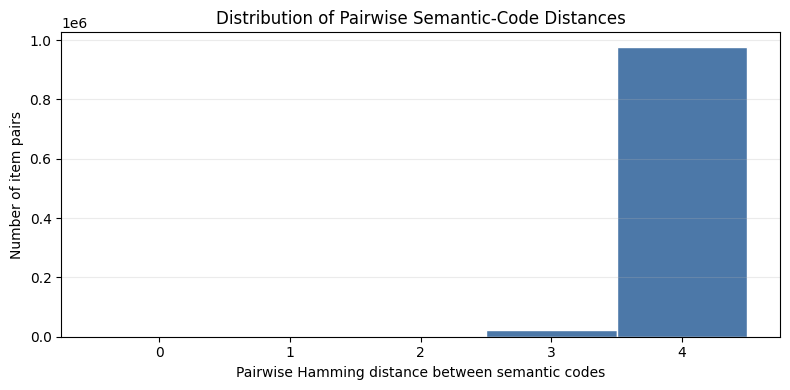

,count,mean,std,min,25%,50%,75%,max
codebook_level,,,,,,,,
0,256.0,47.141,34.431,1.0,20.0,40.0,69.25,199.0
1,256.0,47.141,32.048,2.0,21.0,40.0,70.00,131.0
2,256.0,47.141,46.138,1.0,11.0,28.0,77.25,207.0
3,256.0,47.141,7.229,26.0,43.0,47.0,52.00,68.0


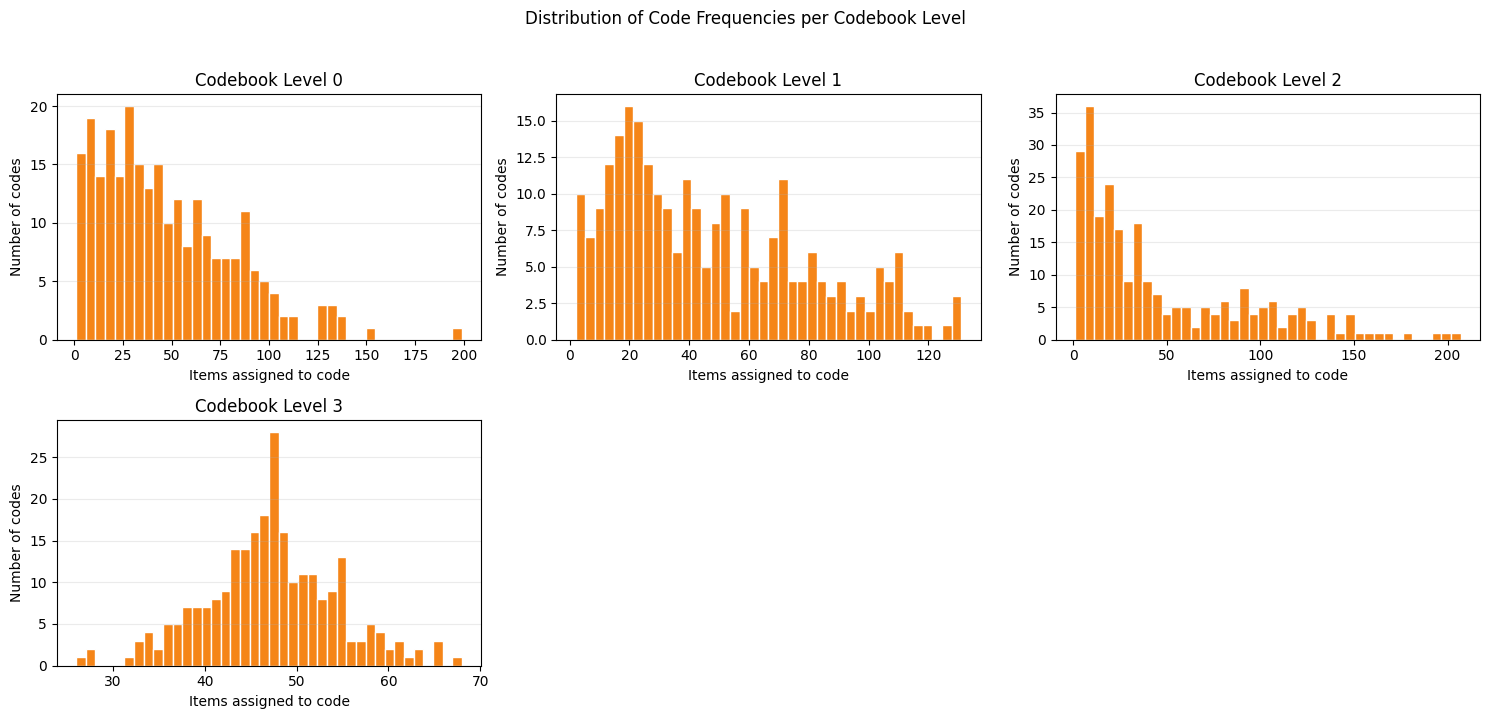

In [44]:
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Semantic-ID diagnostics: pairwise code distances and per-codebook code frequencies.
# For large catalogs, pairwise distances are estimated from sampled item pairs to keep
# the analysis memory-safe.
semantic_codes = np.asarray(
    [semantic_id_mapping[item_id] for item_id in sorted(semantic_id_mapping)],
    dtype=np.int64,
)

if semantic_codes.ndim != 2 or semantic_codes.shape[0] == 0:
    raise ValueError("semantic_id_mapping must contain non-empty, fixed-length code lists.")

num_items, num_codebooks = semantic_codes.shape
max_pair_samples = 1_000_000
rng = np.random.default_rng(42)
num_all_pairs = num_items * (num_items - 1) // 2

if num_all_pairs <= max_pair_samples:
    pair_i, pair_j = np.triu_indices(num_items, k=1)
else:
    pair_i = rng.integers(0, num_items, size=max_pair_samples, endpoint=False)
    pair_j = rng.integers(0, num_items - 1, size=max_pair_samples, endpoint=False)
    pair_j = pair_j + (pair_j >= pair_i)

pairwise_hamming_distances = (semantic_codes[pair_i] != semantic_codes[pair_j]).sum(axis=1)
pairwise_exact_matches = (pairwise_hamming_distances == 0).sum()

print(f"Items: {num_items:,}")
print(f"Codebook levels: {num_codebooks:,}")
print(f"Pairwise distances computed: {len(pairwise_hamming_distances):,} of {num_all_pairs:,} possible pairs")
print(f"Exact semantic-code collisions in computed pairs: {pairwise_exact_matches:,}")
print(
    "Mean / median Hamming distance: "
    f"{pairwise_hamming_distances.mean():.3f} / {np.median(pairwise_hamming_distances):.3f}"
)

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(num_codebooks + 2) - 0.5
ax.hist(pairwise_hamming_distances, bins=bins, color="#4c78a8", edgecolor="white")
ax.set_xticks(range(num_codebooks + 1))
ax.set_xlabel("Pairwise Hamming distance between semantic codes")
ax.set_ylabel("Number of item pairs")
ax.set_title("Distribution of Pairwise Semantic-Code Distances")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

frequency_rows = []
for level in range(num_codebooks):
    counts = Counter(semantic_codes[:, level].tolist())
    for code, frequency in counts.items():
        frequency_rows.append(
            {
                "codebook_level": level,
                "code": code,
                "frequency": frequency,
                "frequency_share": frequency / num_items,
            }
        )

code_frequency_df = pd.DataFrame(frequency_rows)
display(
    code_frequency_df.groupby("codebook_level")["frequency"]
    .describe()
    .round(3)
)

ncols = min(3, num_codebooks)
nrows = math.ceil(num_codebooks / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), squeeze=False)

for level, ax in enumerate(axes.ravel()):
    if level >= num_codebooks:
        ax.axis("off")
        continue

    level_freqs = code_frequency_df.loc[
        code_frequency_df["codebook_level"] == level,
        "frequency",
    ]
    ax.hist(level_freqs, bins=40, color="#f58518", edgecolor="white")
    ax.set_title(f"Codebook Level {level}")
    ax.set_xlabel("Items assigned to code")
    ax.set_ylabel("Number of codes")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Distribution of Code Frequencies per Codebook Level", y=1.02)
plt.tight_layout()
plt.show()


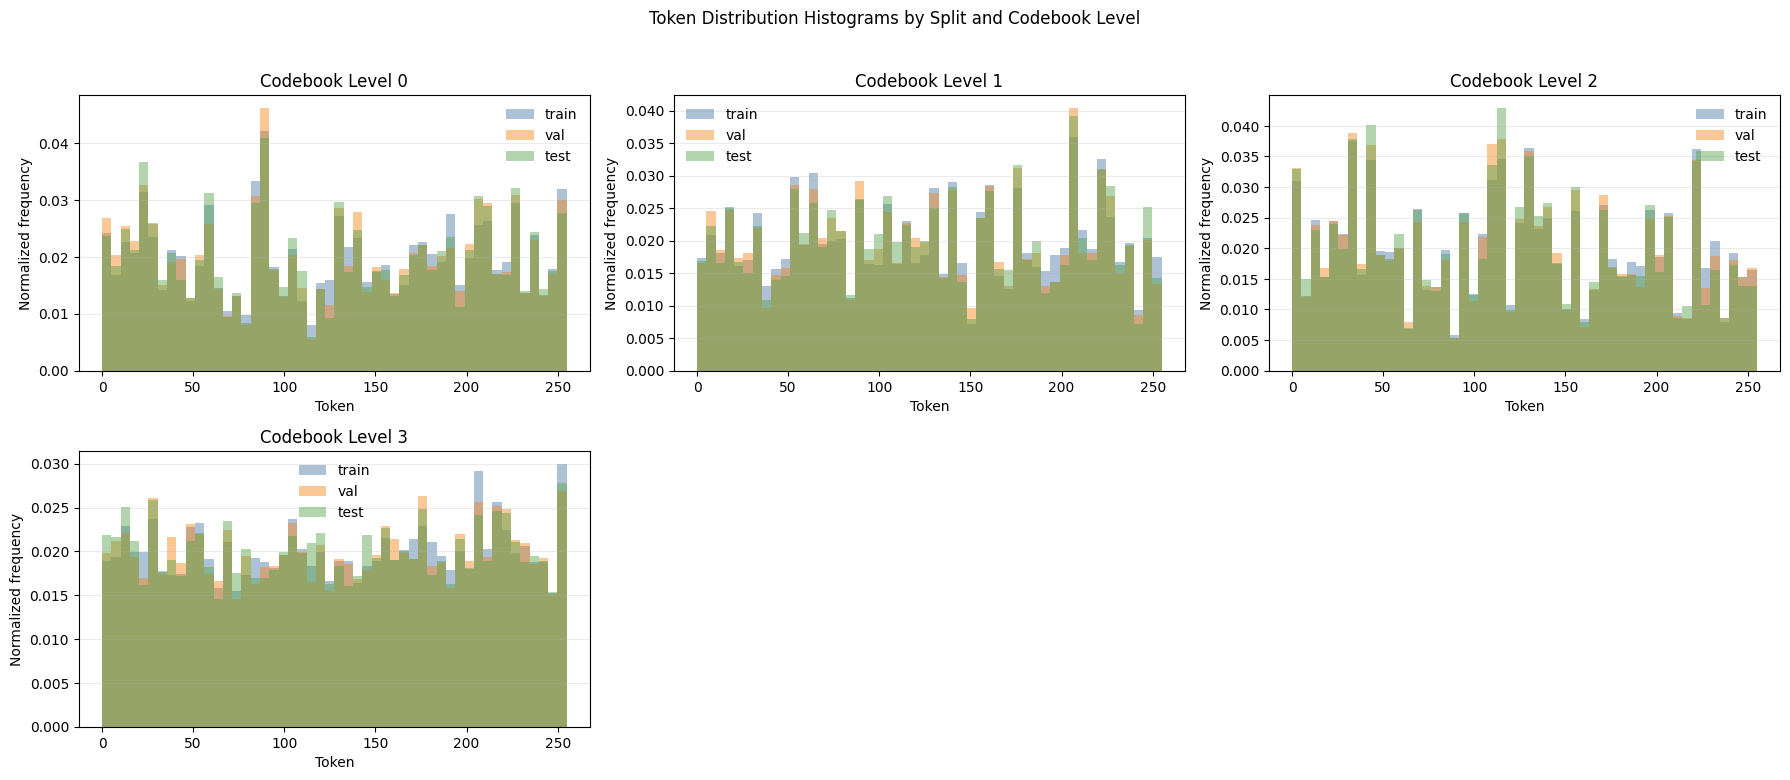

In [45]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

split_datasets = {
    "train": dm.train_dataset,
    "val": dm.val_dataset,
    "test": dm.test_dataset,
}
subset_colors = {
    "train": "#4c78a8",
    "val": "#f58518",
    "test": "#54a24b",
}

if any(dataset is None for dataset in split_datasets.values()):
    raise RuntimeError("Call dm.setup() before plotting split token distributions.")

rows = []
for split_name, dataset in split_datasets.items():
    for example in dataset.examples:
        tokens = semantic_id_mapping.get(str(example.target_raw_item))
        if tokens is None:
            continue
        for level, token in enumerate(tokens):
            rows.append(
                {
                    "split": split_name,
                    "codebook_level": level,
                    "token": int(token),
                }
            )

split_token_df = pd.DataFrame(rows)
if split_token_df.empty:
    raise ValueError("No split target items matched semantic_id_mapping.")

num_levels = int(split_token_df["codebook_level"].max()) + 1
ncols = min(3, num_levels)
nrows = int(np.ceil(num_levels / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.8 * nrows), squeeze=False)

for level, ax in enumerate(axes.ravel()):
    if level >= num_levels:
        ax.axis("off")
        continue

    level_df = split_token_df[split_token_df["codebook_level"] == level]
    token_min = int(level_df["token"].min())
    token_max = int(level_df["token"].max())


    for split_name in ("train", "val", "test"):
        split_tokens = level_df.loc[level_df["split"] == split_name, "token"].to_numpy()
        if len(split_tokens) == 0:
            continue
        weights = np.ones_like(split_tokens, dtype=float) / len(split_tokens)
        ax.hist(
            split_tokens,
            bins=50,
            weights=weights,
            color=subset_colors[split_name],
            alpha=0.45,
            label=split_name,
            edgecolor="none",
        )

    ax.set_title(f"Codebook Level {level}")
    ax.set_xlabel("Token")
    ax.set_ylabel("Normalized frequency")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False)

fig.suptitle("Token Distribution Histograms by Split and Codebook Level", y=1.02)
plt.tight_layout()
plt.show()
